In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={"code_dept": str})
df["date"] = pd.to_datetime(df["date_semaine"] + "-1", format="%G-S%V-%u")

#COMPOSANTES = ["TousAge_asthme_urgences"]
#df["somme_urgences"] = df[COMPOSANTES].sum(axis=1, min_count=1)   # NaN si une composante manque
#CIBLE = "somme_urgences"
CIBLE = "TousAge_asthme_urgences"
EXOS  = ['As in PM10', 'BaP in PM10', 'Cd in PM10',
       'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2',
       'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1',
       'pression_mer', 'tendance_pression_3h', 
       'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite',
       'pression_station', 'precipitation_3h', 'tp_averses_ou_orages',
       'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers',
       'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure',
       'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages',
       'tp_tempete_poussiere_chasse_neige', 'TousAge_allergie_hospitalisation', 
       'TousAge_asthme_hospitalisation', "0an_bronchiolite_urgences", 
       'prev_calc_Maladie_Respi_Chronique_0-14_9',"TousAge_allergie_urgences", 
       'prev_calc_Maladie_Respi_Chronique_15-64_9',
       'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain',
       'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes',
       'pct_ouvriers', 'pct_retraites', 
       'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres',
       'densite_pneumologues', 'densite_allergologues', 'densite_kines',
       'sos_present']

H     = 1                                   # nombre de semaines futures moyennées

# --- Une ligne par département et par semaine t : cible = moyenne de y(t+1)..y(t+H) ---
morceaux = []
for dept, d in df.groupby("code_dept"):
    d = d.drop_duplicates("date").set_index("date").sort_index().asfreq("W-MON")
    y, sem = d[CIBLE], d.index.isocalendar().week.astype(float)
    moy_glis = y.rolling(H, min_periods=H).mean()          # moyenne de y(t-H+1)..y(t), NaN si un trou
    morceaux.append(pd.DataFrame({
        "code_dept": dept,
        "date_debut": d.index + pd.Timedelta(weeks=1),      # première semaine de la fenêtre cible
        "date_fin":   d.index + pd.Timedelta(weeks=H),      # dernière semaine de la fenêtre cible
        "cible":      moy_glis.shift(-H),                   # moyenne de y(t+1)..y(t+H)
        "y_passe":    moy_glis,                             # moyenne des H dernières semaines connues
        "y_lag0": y, "y_lag1": y.shift(1), "y_lag2": y.shift(2),
        "sem_sin": np.sin(2 * np.pi * sem / 52.18),
        "sem_cos": np.cos(2 * np.pi * sem / 52.18),
        **{c: d[c] for c in EXOS},
    }))
panel = pd.concat(morceaux).dropna(subset=["cible", "y_passe", "y_lag0", "y_lag1", "y_lag2"])

# --- Split sur l'année de la DERNIÈRE semaine de la fenêtre (pas de chevauchement train/val) ---
an = panel["date_fin"].dt.year
panel["split"] = np.select([an <= 2022, an == 2023], ["train", "val"], default="test")

# --- Baselines sur la même cible agrégée ---
# 1) persistance : la moyenne des H semaines à venir vaut celle des H semaines passées
panel["base_persist"] = panel["y_passe"]
# 2) profil saisonnier : moyenne de la cible sur le train, par département et semaine de début
panel["sem_debut"] = panel["date_debut"].dt.isocalendar().week.astype(int)
profil = (panel[panel["split"] == "train"]
          .groupby(["code_dept", "sem_debut"])["cible"].mean().rename("base_saison"))
panel = panel.join(profil, on=["code_dept", "sem_debut"])

def scores(y_vrai, y_pred):
    return {"R2": r2_score(y_vrai, y_pred),
            "MAE": mean_absolute_error(y_vrai, y_pred),
            "RMSE": mean_squared_error(y_vrai, y_pred) ** 0.5}

val = panel[panel["split"] == "val"].dropna(subset=["base_saison"])
print(panel["split"].value_counts())
print("Persistance :", scores(val["cible"], val["base_persist"]))
print("Profil sais.:", scores(val["cible"], val["base_saison"]))

split
train    9696
val      4992
test     4992
Name: count, dtype: int64
Persistance : {'R2': 0.4622693063340212, 'MAE': 263.2236892592448, 'RMSE': 376.5929746172903}
Profil sais.: {'R2': 0.5144792565338587, 'MAE': 252.30392629169552, 'RMSE': 357.8439634026693}


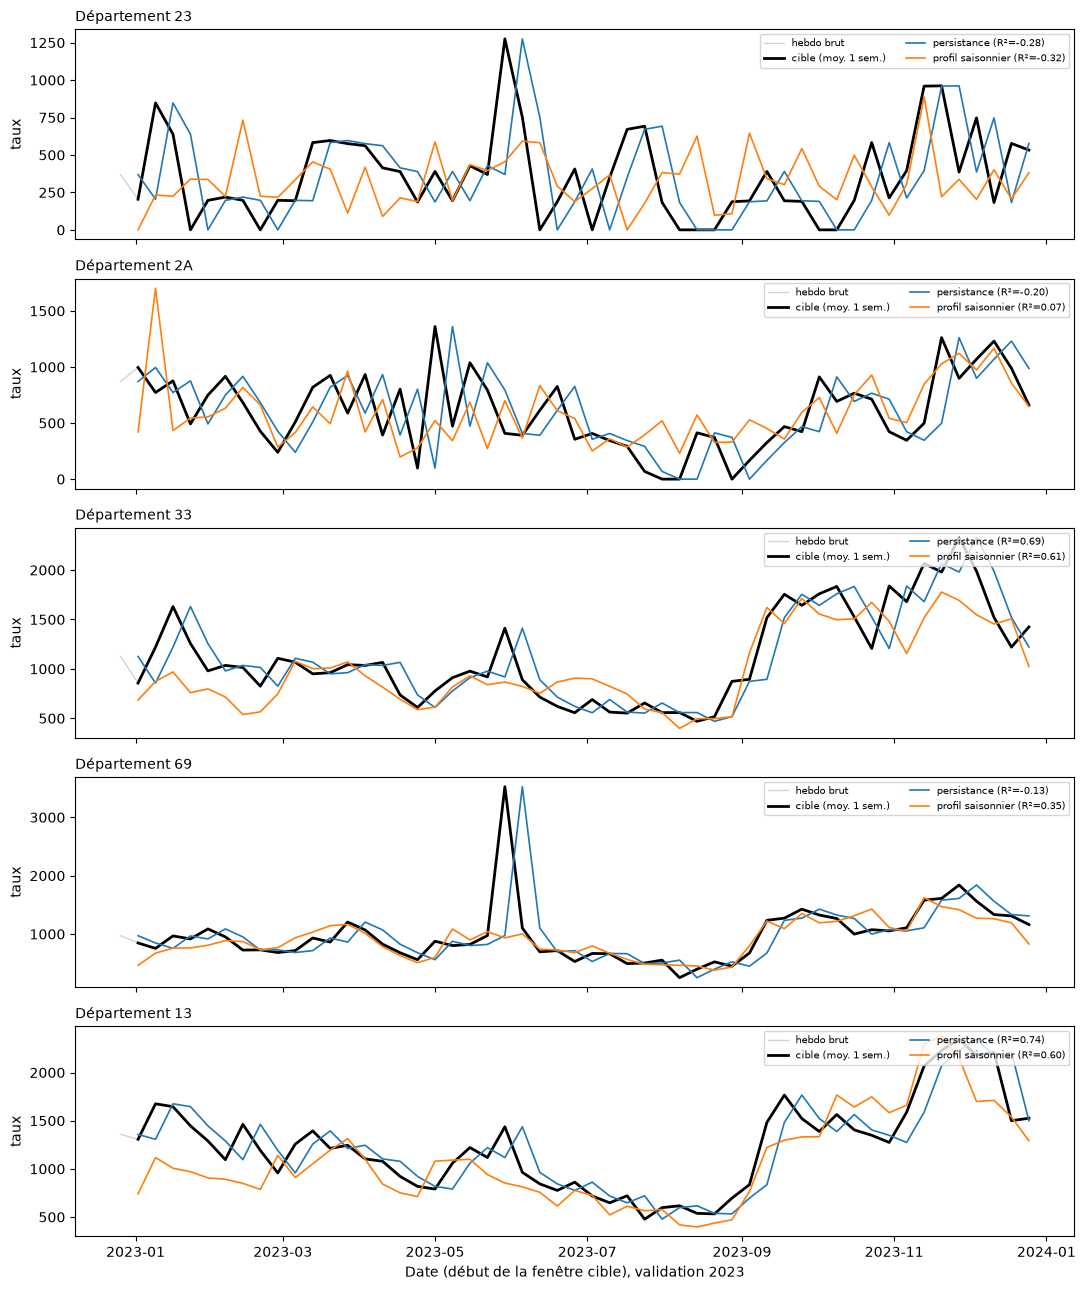

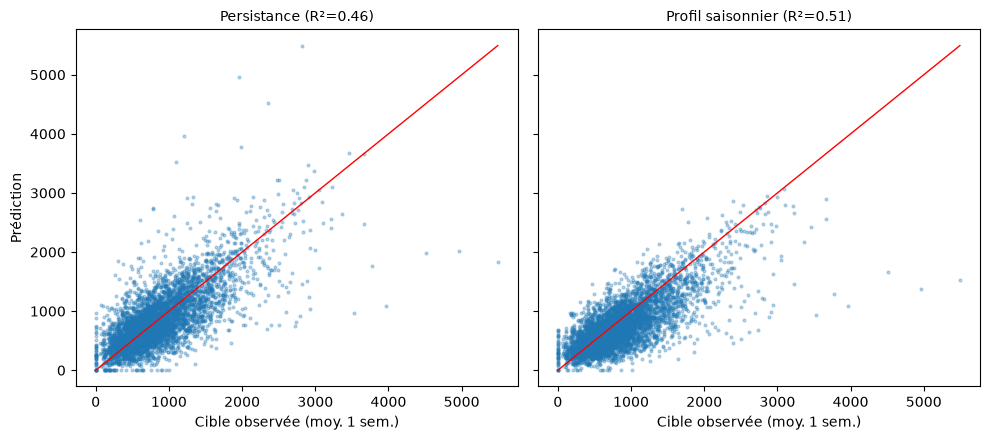

In [21]:
import matplotlib.pyplot as plt

DEPTS = ["23", "2A", "33", "69", "13"]          # départements à afficher

fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = val[val["code_dept"] == dept].sort_values("date_debut")
    sc_p = scores(v["cible"], v["base_persist"])["R2"]
    sc_s = scores(v["cible"], v["base_saison"])["R2"]
    # valeur hebdomadaire brute de la semaine t (y_lag0), placée à sa propre date
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["date_debut"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    ax.plot(v["date_debut"], v["base_persist"], color="tab:blue", lw=1.2,
            label=f"persistance (R²={sc_p:.2f})")
    ax.plot(v["date_debut"], v["base_saison"], color="tab:orange", lw=1.2,
            label=f"profil saisonnier (R²={sc_s:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (début de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

# --- Vue d'ensemble, tous départements : prédit vs observé ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, col, nom in zip(axes, ["base_persist", "base_saison"], ["Persistance", "Profil saisonnier"]):
    ax.scatter(val["cible"], val[col], s=4, alpha=0.3)
    lim = [0, val[["cible", col]].max().max()]
    ax.plot(lim, lim, color="red", lw=1)                 # diagonale y = x
    ax.set_title(f"{nom} (R²={scores(val['cible'], val[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

#FEATURES = ["profil", "y_lag0", "y_lag1", "y_lag2", "sem_sin", "sem_cos", "code_dept"] + EXOS

FEATURES = ["y_lag0", "y_lag1", "y_lag2", "sem_sin", "sem_cos"] + EXOS
CAT = []
NUM = [c for c in FEATURES if c not in CAT]

prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT),
])
modele = Pipeline([("prep", prep), ("reg", LinearRegression())])

train = panel[panel["split"] == "train"].dropna(subset=FEATURES + ["cible"])
val_m = panel[panel["split"] == "val"].dropna(subset=FEATURES + ["cible"])

modele.fit(train[FEATURES], train["cible"])
print("LR val :", scores(val_m["cible"], modele.predict(val_m[FEATURES])))

LR val : {'R2': 0.5724870634173754, 'MAE': 235.95991794550423, 'RMSE': 335.23789405359906}


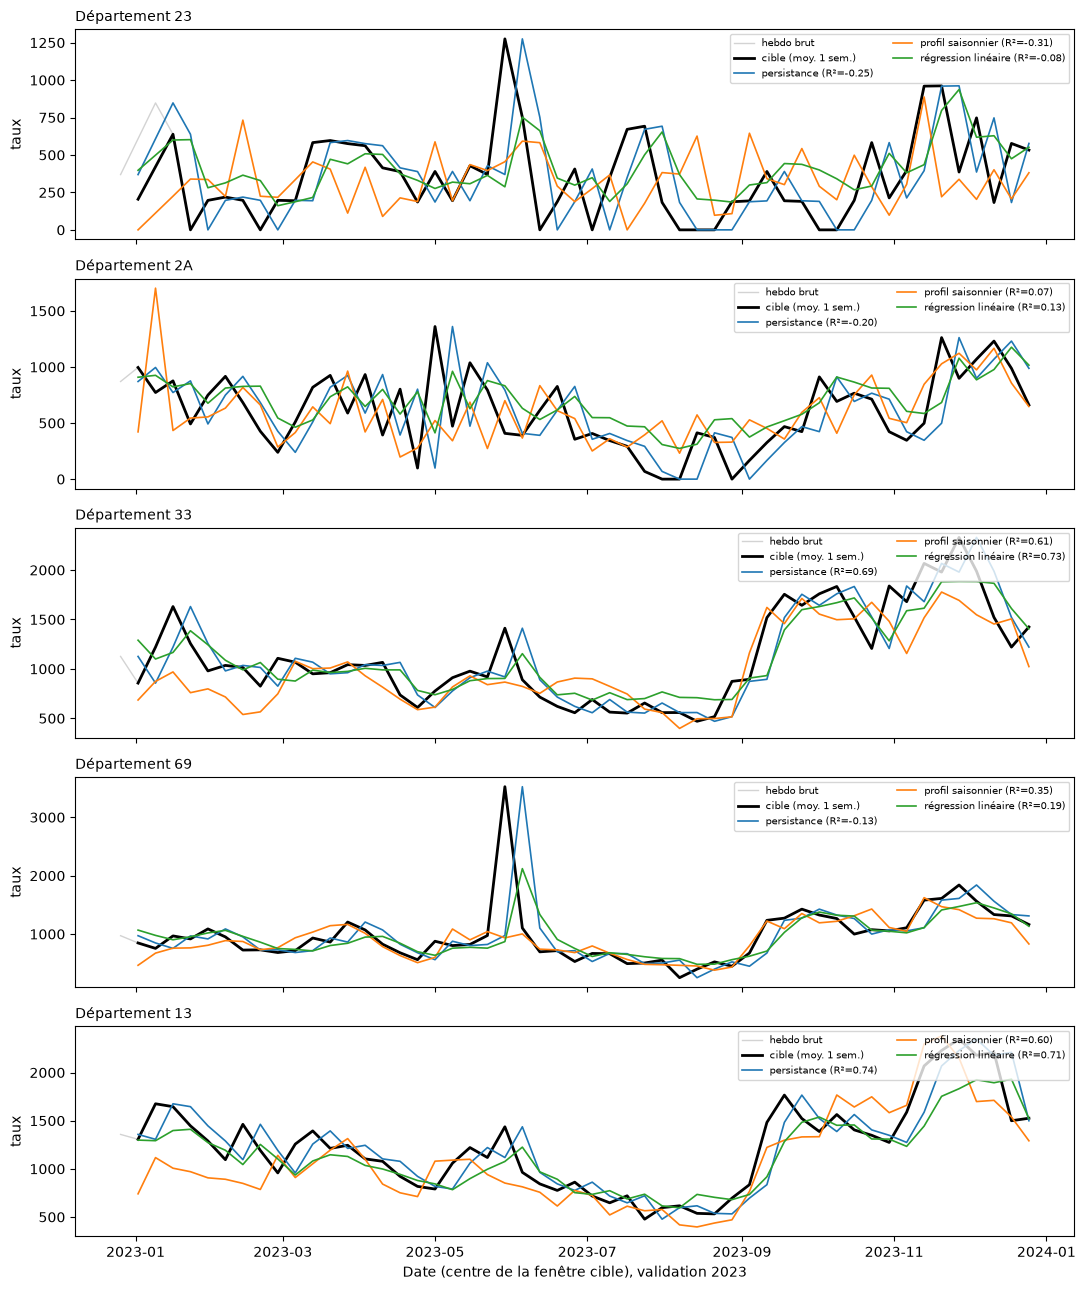

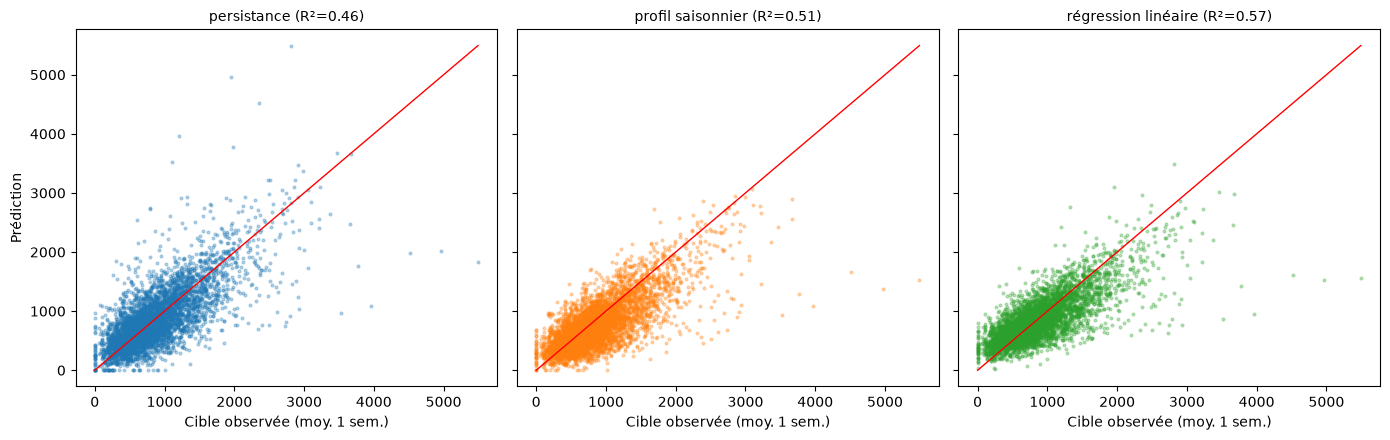

In [23]:
import matplotlib.pyplot as plt

# Prédictions du modèle sur la validation, mêmes lignes que les baselines
v_all = val_m.dropna(subset=["base_saison"]).copy()
v_all["pred_LR"] = modele.predict(v_all[FEATURES])
v_all["centre"] = v_all["date_debut"] + pd.Timedelta(weeks=(H - 1) / 2)

SERIES = [("base_persist", "persistance", "tab:blue"),
          ("base_saison",  "profil saisonnier", "tab:orange"),
          ("pred_LR",      "régression linéaire", "tab:green")]

# --- Séries temporelles par département ---
fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = v_all[v_all["code_dept"] == dept].sort_values("date_debut")
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["centre"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    for col, nom, coul in SERIES:
        r2 = scores(v["cible"], v[col])["R2"]
        ax.plot(v["centre"], v[col], color=coul, lw=1.2, label=f"{nom} (R²={r2:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (centre de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

# --- Vue d'ensemble, tous départements : prédit vs observé ---
fig, axes = plt.subplots(1, len(SERIES), figsize=(14, 4.5), sharex=True, sharey=True)
lim = [0, v_all[["cible"] + [c for c, _, _ in SERIES]].max().max()]
for ax, (col, nom, coul) in zip(axes, SERIES):
    ax.scatter(v_all["cible"], v_all[col], s=4, alpha=0.3, color=coul)
    ax.plot(lim, lim, color="red", lw=1)                   # diagonale y = x
    ax.set_title(f"{nom} (R²={scores(v_all['cible'], v_all[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

Silhouette : {2: 0.556, 3: 0.594, 4: 0.454, 5: 0.502, 6: 0.484} -> k = 3
         r2_persist  r2_saison  n_dept
cluster                               
0              0.40      -3.37       6
1              0.42       0.04      67
2             -0.42      -0.81      23


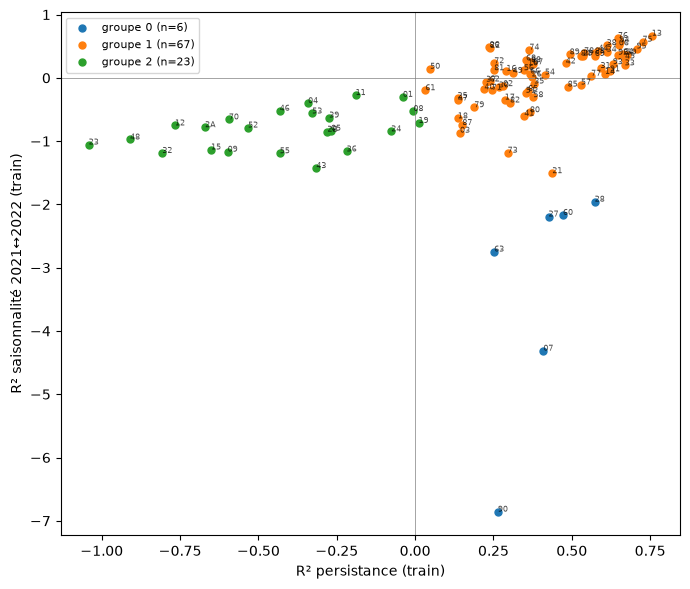

       persistance  profil  LR globale  LR par groupe
0            0.433   0.139       0.547          0.486
1            0.476   0.552       0.571          0.577
2           -0.191  -0.049       0.142          0.164
TOTAL        0.462   0.514       0.572          0.576


In [24]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# --- 1) Indicateurs par département, sur le train uniquement (valeur hebdo brute y_lag0 en t) ---
brut = panel.loc[panel["split"] == "train", ["code_dept", "y_lag0"]].copy()
iso = brut.index.isocalendar()
brut["an"], brut["sem"] = iso.year.values, iso.week.values

def indicateurs(d):
    # Persistance : y(t) prédit par y(t-1)
    y = d.sort_index()["y_lag0"]
    paire = pd.concat([y.shift(1), y], axis=1, keys=["prec", "act"]).dropna()
    r2_persist = r2_score(paire["act"], paire["prec"])
    # Saisonnalité : 2022 prédit par 2021, 2021 prédit par 2022, moyenne des deux R²
    piv = d.pivot_table(index="sem", columns="an", values="y_lag0")
    if not {2021, 2022} <= set(piv.columns):
        return pd.Series({"r2_persist": r2_persist, "r2_saison": np.nan})
    a = piv[[2021, 2022]].dropna()                     # semaines présentes les deux années
    r2_saison = (r2_score(a[2022], a[2021]) + r2_score(a[2021], a[2022])) / 2
    return pd.Series({"r2_persist": r2_persist, "r2_saison": r2_saison})

ind = brut.groupby("code_dept").apply(indicateurs).dropna()

# --- 2) KMeans sur les deux indicateurs, nombre de groupes choisi par silhouette ---
X = StandardScaler().fit_transform(ind[["r2_persist", "r2_saison"]])
sil = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=0).fit_predict(X)) for k in range(2, 7)}
k_opt = max(sil, key=sil.get)
ind["cluster"] = KMeans(k_opt, n_init=20, random_state=0).fit_predict(X)
print("Silhouette :", {k: round(v, 3) for k, v in sil.items()}, "-> k =", k_opt)
print(ind.groupby("cluster")[["r2_persist", "r2_saison"]].mean().round(2)
         .assign(n_dept=ind["cluster"].value_counts().sort_index()))

fig, ax = plt.subplots(figsize=(7, 6))
for k, g in ind.groupby("cluster"):
    ax.scatter(g["r2_persist"], g["r2_saison"], s=25, label=f"groupe {k} (n={len(g)})")
    for dept, r in g.iterrows():
        ax.annotate(dept, (r["r2_persist"], r["r2_saison"]), fontsize=6, alpha=0.7)
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("R² persistance (train)"); ax.set_ylabel("R² saisonnalité 2021↔2022 (train)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# --- 3) Modèle global vs un modèle par groupe, mêmes lignes de validation ---
panel = panel.drop(columns="cluster", errors="ignore").join(ind["cluster"], on="code_dept")
train = panel[panel["split"] == "train"].dropna(subset=FEATURES + ["cible", "cluster"])
val_m = panel[panel["split"] == "val"].dropna(subset=FEATURES + ["cible", "cluster", "base_saison"]).copy()

val_m["pred_global"] = clone(modele).fit(train[FEATURES], train["cible"]).predict(val_m[FEATURES])
val_m["pred_groupe"] = np.nan
for k, tr_k in train.groupby("cluster"):
    m_k = clone(modele).fit(tr_k[FEATURES], tr_k["cible"])
    sel = (val_m["cluster"] == k).values
    val_m.loc[sel, "pred_groupe"] = m_k.predict(val_m.loc[sel, FEATURES])

# --- 4) R² par groupe et au total ---
cols = {"persistance": "base_persist", "profil": "base_saison",
        "LR globale": "pred_global", "LR par groupe": "pred_groupe"}
res = {k: {nom: scores(g["cible"], g[c])["R2"] for nom, c in cols.items()}
       for k, g in val_m.groupby("cluster")}
res["TOTAL"] = {nom: scores(val_m["cible"], val_m[c])["R2"] for nom, c in cols.items()}
print(pd.DataFrame(res).T.round(3))

Départements avec NaN dans les variables actives : []
Variance expliquée (%) : [31.5 16.3 13.8  8.6  6.4  5.3]

Variables actives :
                                             CP1   CP2   CP3
pct_retraites                             -0.81  0.49 -0.09
pct_agriculteurs                          -0.71  0.38 -0.21
pct_ouvriers                              -0.67 -0.46  0.04
prev_calc_Maladie_Respi_Chronique_15-64_9 -0.48 -0.04  0.80
prev_calc_Maladie_Respi_Chronique_65+_9   -0.14 -0.12  0.87
pct_artisans                              -0.00  0.79 -0.12
pct_employes                               0.05 -0.26  0.50
prev_calc_Maladie_Respi_Chronique_0-14_9   0.07  0.27  0.58
densite_generalistes                       0.32  0.68  0.09
densite_pneumologues                       0.41  0.31  0.48
densite_kines                              0.44  0.79  0.10
sos_present                                0.44 -0.15  0.11
densite_allergologues                      0.45  0.07  0.02
pct_prof_inter             

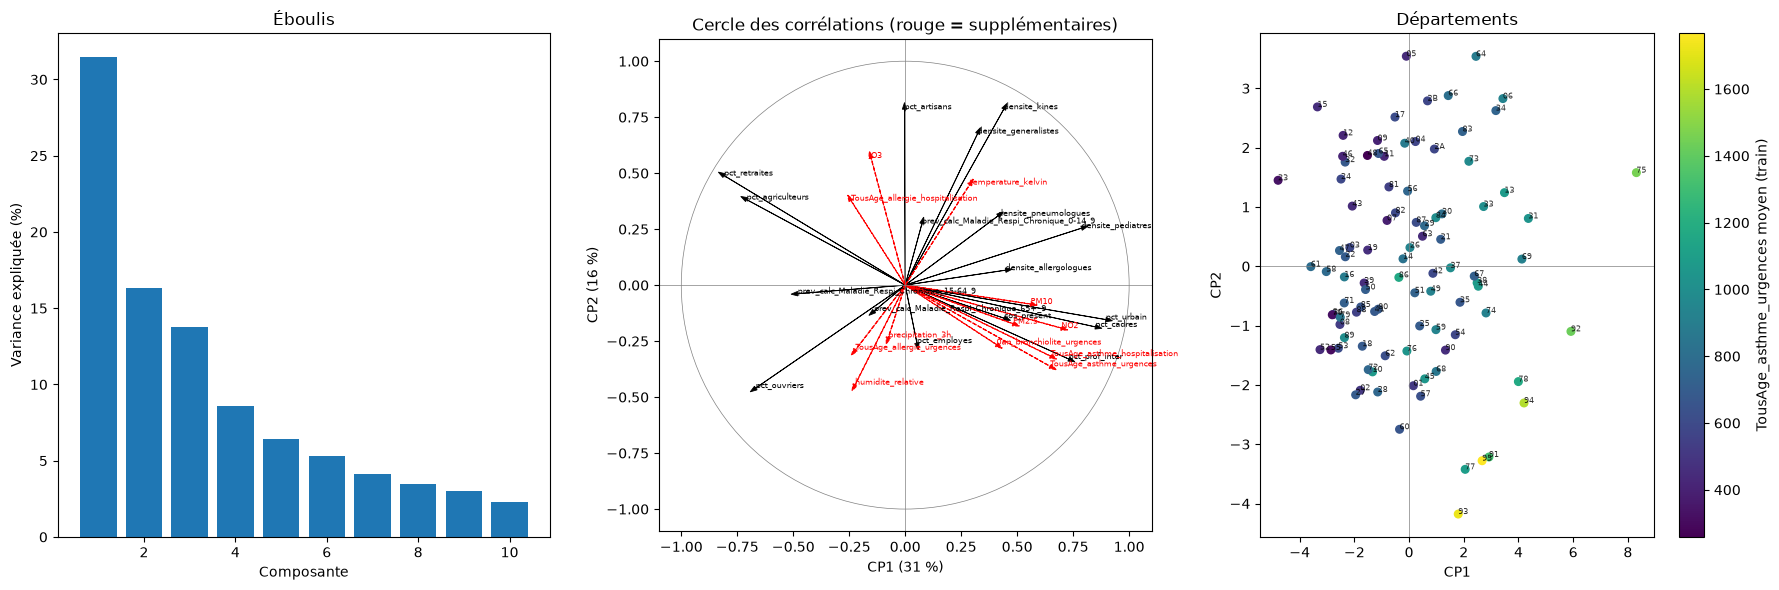

In [25]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- 1) Table départementale : moyennes sur le train uniquement ---
IDENTITE = [c for c in EXOS if c.startswith(("pct_", "prev_calc_", "densite_"))] + ["sos_present"]
SUPPL = ["temperature_kelvin", "humidite_relative", "precipitation_3h",
         "NO2", "O3", "PM10", "PM2.5",
         "TousAge_allergie_urgences", "TousAge_asthme_hospitalisation",
         "0an_bronchiolite_urgences", "TousAge_allergie_hospitalisation"]

tr = panel[panel["split"] == "train"]
dep = (tr.groupby("code_dept")[IDENTITE + SUPPL + ["y_lag0"]].mean()
         .rename(columns={"y_lag0": CIBLE}))                 # y_lag0 = taux brut de la semaine t
print("Départements avec NaN dans les variables actives :",
      dep.index[dep[IDENTITE].isna().any(axis=1)].tolist())
dep = dep.dropna(subset=IDENTITE)

# --- 2) ACP sur les variables actives standardisées ---
Z = StandardScaler().fit_transform(dep[IDENTITE])
pca = PCA().fit(Z)
coord = pd.DataFrame(pca.transform(Z), index=dep.index,
                     columns=[f"CP{i+1}" for i in range(Z.shape[1])])
print("Variance expliquée (%) :", (100 * pca.explained_variance_ratio_[:6]).round(1))

# Corrélations variables actives / composantes
cor_act = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_),
                       index=IDENTITE, columns=coord.columns)
# Corrélations variables supplémentaires / composantes (NaN ignorés)
cor_sup = pd.DataFrame({cp: dep[SUPPL + [CIBLE]].corrwith(coord[cp]) for cp in coord.columns[:3]})
print("\nVariables actives :\n", cor_act.iloc[:, :3].round(2).sort_values("CP1"))
print("\nVariables supplémentaires :\n", cor_sup.round(2).sort_values("CP1"))

# --- 3) Figures ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Éboulis
ax = axes[0]
ax.bar(range(1, 11), 100 * pca.explained_variance_ratio_[:10])
ax.set_xlabel("Composante"); ax.set_ylabel("Variance expliquée (%)"); ax.set_title("Éboulis")

# Cercle des corrélations CP1 x CP2
ax = axes[1]
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey", lw=0.5))
for v, r in cor_act.iterrows():
    ax.arrow(0, 0, r["CP1"], r["CP2"], color="black", head_width=0.02, lw=0.6)
    ax.annotate(v, (r["CP1"], r["CP2"]), fontsize=6)
for v, r in cor_sup.iterrows():
    ax.arrow(0, 0, r["CP1"], r["CP2"], color="red", head_width=0.02, lw=0.8, ls="--")
    ax.annotate(v, (r["CP1"], r["CP2"]), fontsize=6, color="red")
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel(f"CP1 ({100*pca.explained_variance_ratio_[0]:.0f} %)")
ax.set_ylabel(f"CP2 ({100*pca.explained_variance_ratio_[1]:.0f} %)")
ax.set_title("Cercle des corrélations (rouge = supplémentaires)")

# Départements dans le plan CP1 x CP2, colorés par l'incidence moyenne d'allergies
ax = axes[2]
sc = ax.scatter(coord["CP1"], coord["CP2"], c=dep[CIBLE], cmap="viridis", s=30)
for d, r in coord.iterrows():
    ax.annotate(d, (r["CP1"], r["CP2"]), fontsize=6, alpha=0.8)
plt.colorbar(sc, ax=ax, label=f"{CIBLE} moyen (train)")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("CP1"); ax.set_ylabel("CP2"); ax.set_title("Départements")

plt.tight_layout()
plt.show()

In [26]:
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict, LeaveOneOut

# =====================================================================================
# 1) Quelles pathologies le profil des départements explique-t-il ?
#    Pour chaque pathologie, on prédit son taux moyen 2021-2022 par département
#    à partir des n premières composantes de l'ACP (n = 1 à 5).
#    Leave-one-out : chaque département est prédit par un modèle qui ne l'a pas vu.
#    R² proche de 0 = le profil n'explique rien ; R² élevé = il explique les écarts.
# =====================================================================================
CIBLES_TEST = [CIBLE, "TousAge_allergie_urgences", "TousAge_asthme_hospitalisation",
               "0an_bronchiolite_urgences", "TousAge_allergie_hospitalisation"]

res = {}
for cib in CIBLES_TEST:
    ok = dep[cib].notna()                                    # départements où la pathologie est renseignée
    res[cib] = {f"{n} CP": r2_score(dep.loc[ok, cib],
                                    cross_val_predict(LinearRegression(),
                                                      coord.loc[ok].iloc[:, :n],   # n premières composantes
                                                      dep.loc[ok, cib], cv=LeaveOneOut()))
                for n in [1, 2, 3, 4, 5]}
print("R² leave-one-out selon le nombre de composantes :")
print(pd.DataFrame(res).T.round(3))

# =====================================================================================
# 2) Pour l'asthme aux urgences (la pathologie la mieux expliquée) :
#    quels axes de l'ACP, puis quelles variables d'origine, vont avec son niveau ?
#    Corrélations simples, une variable à la fois : elles se recoupent entre elles.
# =====================================================================================
CIBLE_A = "TousAge_asthme_urgences"
ok = dep[CIBLE_A].notna()
X_id, y_a = dep.loc[ok, IDENTITE], dep.loc[ok, CIBLE_A]      # variables d'identité et cible, par département

print("\nCorrélation asthme moyen / composantes :")
print(coord.loc[ok].iloc[:, :5].corrwith(y_a).round(2))

print("\nCorrélation asthme moyen / variables d'identité :")
print(X_id.corrwith(y_a).round(2).sort_values())

# =====================================================================================
# 3) Modèle explicatif parcimonieux : Lasso sur les variables d'identité.
#    Le Lasso met à zéro les variables redondantes et ne garde que celles qui comptent.
#    Sa pénalité (alpha) est choisie par validation croisée interne (LassoCV),
#    elle-même refaite dans chaque pli du leave-one-out : le R² reste honnête.
# =====================================================================================
lasso = Pipeline([("sc", StandardScaler()),                  # variables standardisées : coefficients comparables
                  ("las", LassoCV(cv=5, random_state=0, max_iter=50000))])

pred = cross_val_predict(lasso, X_id, y_a, cv=LeaveOneOut())  # prédictions LOO (réutilisées plus loin)
print(f"\nLasso, R² LOO = {r2_score(y_a, pred):.3f}")

# Ajustement sur tous les départements, pour lire les variables retenues et leur poids
lasso.fit(X_id, y_a)
coefs = pd.Series(lasso.named_steps["las"].coef_, index=IDENTITE)
print("alpha retenu :", round(lasso.named_steps["las"].alpha_, 3))
print("Variables retenues (effet d'un écart-type, en taux / 100 000 passages) :")
print(coefs[coefs != 0].round(1).sort_values())

R² leave-one-out selon le nombre de composantes :
                                   1 CP   2 CP   3 CP   4 CP   5 CP
TousAge_asthme_urgences           0.396  0.518  0.509  0.490  0.556
TousAge_allergie_urgences         0.009  0.078  0.065  0.038  0.046
TousAge_asthme_hospitalisation    0.395  0.490  0.484  0.471  0.555
0an_bronchiolite_urgences         0.136  0.195  0.181  0.158  0.135
TousAge_allergie_hospitalisation -0.005  0.126  0.122  0.088  0.121

Corrélation asthme moyen / composantes :
CP1    0.65
CP2   -0.36
CP3    0.02
CP4    0.05
CP5    0.25
dtype: float64

Corrélation asthme moyen / variables d'identité :
pct_retraites                               -0.70
pct_agriculteurs                            -0.58
pct_ouvriers                                -0.38
prev_calc_Maladie_Respi_Chronique_15-64_9   -0.25
pct_artisans                                -0.24
densite_generalistes                        -0.13
prev_calc_Maladie_Respi_Chronique_65+_9     -0.11
densite_kines           

Fréquence de sélection (%) :
 pct_urbain                                   100.0
sos_present                                   95.0
pct_cadres                                    92.0
densite_kines                                 89.0
prev_calc_Maladie_Respi_Chronique_65+_9       84.0
pct_retraites                                 82.0
densite_allergologues                         80.0
densite_generalistes                          79.0
prev_calc_Maladie_Respi_Chronique_0-14_9      78.0
densite_pneumologues                          75.0
pct_employes                                  74.0
prev_calc_Maladie_Respi_Chronique_15-64_9     71.0
pct_ouvriers                                  67.0
pct_prof_inter                                60.0
pct_agriculteurs                              57.0
pct_artisans                                  56.0
densite_pediatres                             49.0
dtype: float64

Lasso sans IdF, R² LOO = 0.416
LR sur ['pct_urbain', 'pct_cadres', 'pct_retraites'], R²

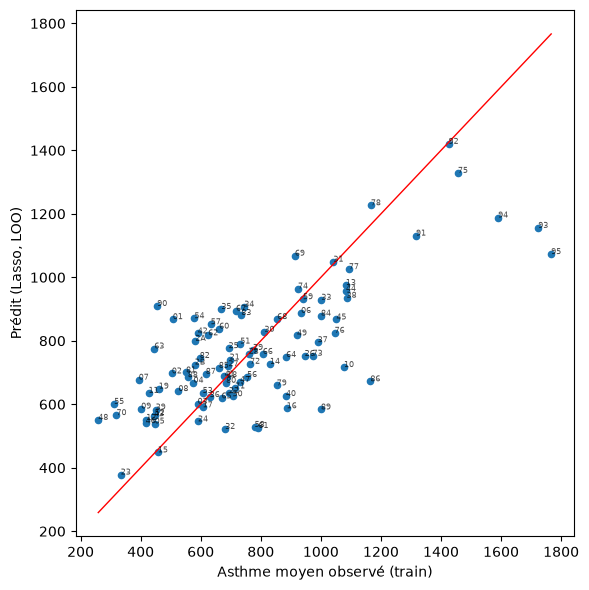

In [27]:
from sklearn.linear_model import LinearRegression

# --- 1) Stabilité : fréquence de sélection sur 200 bootstraps ---
rng = np.random.default_rng(0)
sel = pd.Series(0, index=IDENTITE)
for _ in range(200):
    i = rng.choice(len(X_id), len(X_id), replace=True)
    m = clone(lasso).fit(X_id.iloc[i], y_a.iloc[i])
    sel += (m.named_steps["las"].coef_ != 0)
print("Fréquence de sélection (%) :\n", (100 * sel / 200).round(0).sort_values(ascending=False))

# --- 2) Points influents : sans l'Île-de-France ---
idf = ["75", "77", "78", "91", "92", "93", "94", "95"]
hors = ~X_id.index.isin(idf)
pred_h = cross_val_predict(lasso, X_id[hors], y_a[hors], cv=LeaveOneOut())
print(f"\nLasso sans IdF, R² LOO = {r2_score(y_a[hors], pred_h):.3f}")

# --- 3) Modèle minimal : régression ordinaire sur les trois pct_ ---
TROIS = ["pct_urbain", "pct_cadres", "pct_retraites"]
pred_3 = cross_val_predict(LinearRegression(), X_id[TROIS], y_a, cv=LeaveOneOut())
print(f"LR sur {TROIS}, R² LOO = {r2_score(y_a, pred_3):.3f}")

# --- Observé vs prédit (LOO, Lasso complet) ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_a, pred, s=20)
for d in y_a.index:
    ax.annotate(d, (y_a[d], pred[y_a.index.get_loc(d)]), fontsize=6, alpha=0.7)
lim = [y_a.min(), y_a.max()]
ax.plot(lim, lim, color="red", lw=1)
ax.set_xlabel("Asthme moyen observé (train)"); ax.set_ylabel("Prédit (Lasso, LOO)")
plt.tight_layout(); plt.show()


Départements sans valeur : []


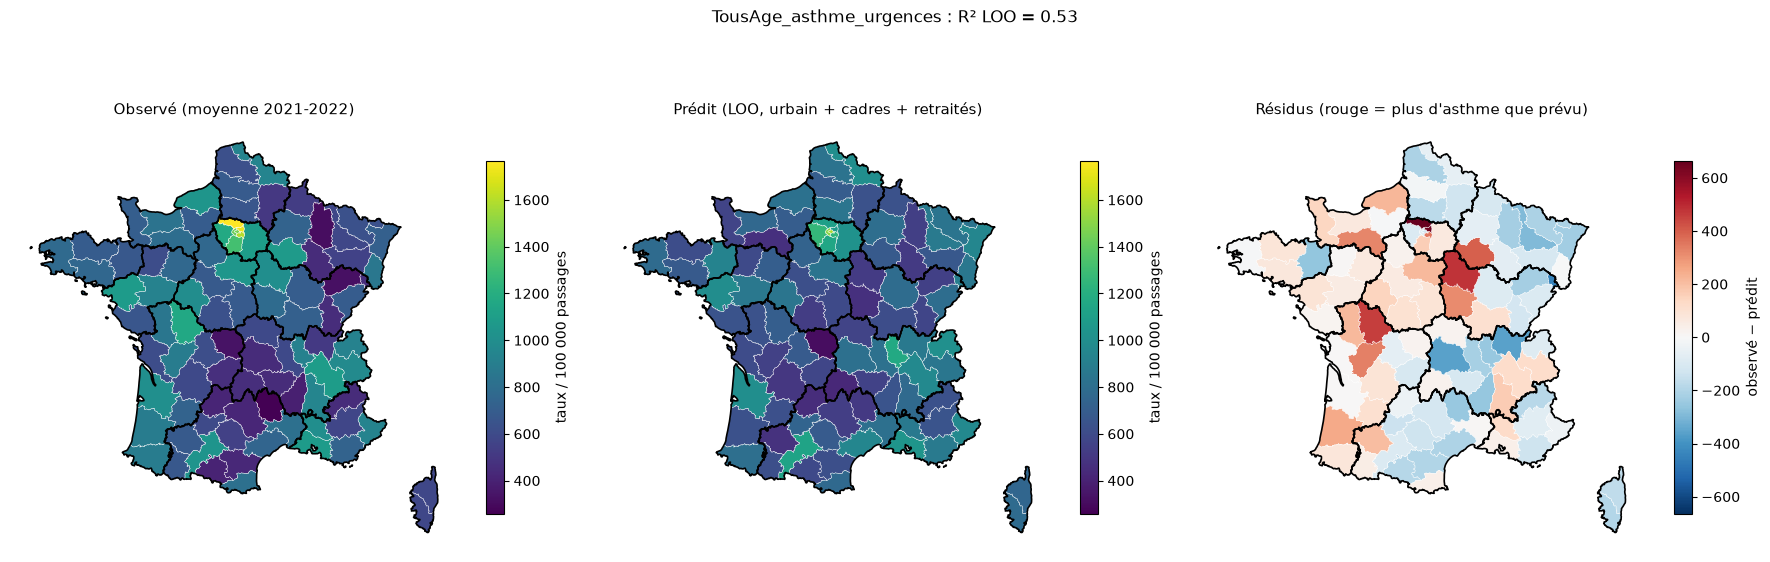

Plus d'asthme que prévu :
 code               nom  observe  predit  residu
  95        Val-d'Oise   1767.0  1103.0   664.0
  93 Seine-Saint-Denis   1724.0  1077.0   647.0
  89             Yonne   1000.0   518.0   482.0
  86            Vienne   1165.0   706.0   459.0
  10              Aube   1077.0   680.0   397.0
  94      Val-de-Marne   1590.0  1239.0   351.0
  16          Charente    886.0   551.0   336.0
  61              Orne    792.0   468.0   324.0

Moins d'asthme que prévu :
 code                   nom  observe  predit  residu
  90 Territoire de Belfort    455.0   898.0  -443.0
  63           Puy-de-Dôme    445.0   807.0  -362.0
  01                   Ain    507.0   866.0  -359.0
  54    Meurthe-et-Moselle    579.0   873.0  -294.0
  35       Ille-et-Vilaine    669.0   931.0  -262.0
  07               Ardèche    394.0   649.0  -255.0
  69                 Rhône    914.0  1168.0  -254.0
  48                Lozère    259.0   509.0  -250.0


In [28]:
import geopandas as gpd
from matplotlib.colors import TwoSlopeNorm

# --- Correspondance département -> région (découpage 2016) ---
REGIONS = {
    "ARA": ["01","03","07","15","26","38","42","43","63","69","73","74"],
    "BFC": ["21","25","39","58","70","71","89","90"],
    "BRE": ["22","29","35","56"],
    "CVL": ["18","28","36","37","41","45"],
    "COR": ["2A","2B"],
    "GES": ["08","10","51","52","54","55","57","67","68","88"],
    "HDF": ["02","59","60","62","80"],
    "IDF": ["75","77","78","91","92","93","94","95"],
    "NOR": ["14","27","50","61","76"],
    "NAQ": ["16","17","19","23","24","33","40","47","64","79","86","87"],
    "OCC": ["09","11","12","30","31","32","34","46","48","65","66","81","82"],
    "PDL": ["44","49","53","72","85"],
    "PAC": ["04","05","06","13","83","84"],
}
dept_region = {d: r for r, ds in REGIONS.items() for d in ds}

# --- 1) Fond de carte des départements métropolitains, et contours des régions ---
URL = ("https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/"
       "departements-version-simplifiee.geojson")
carte = gpd.read_file(URL)[["code", "nom", "geometry"]]
carte["region"] = carte["code"].map(dept_region)
regions = carte[["region", "geometry"]].dissolve(by="region")   # fusion des départements de chaque région

# --- 2) Observé, prédit (LOO, LR sur les trois pct_) et résidus ---
res = pd.DataFrame({"observe": y_a, "predit": pred_3}, index=y_a.index)
res["residu"] = res["observe"] - res["predit"]
carte = carte.merge(res, left_on="code", right_index=True, how="left")
print("Départements sans valeur :", carte.loc[carte["observe"].isna(), "code"].tolist())

# --- 3) Trois cartes : observé et prédit sur la même échelle, résidus centrés sur 0 ---
vmin, vmax = carte[["observe", "predit"]].min().min(), carte[["observe", "predit"]].max().max()
lim_r = carte["residu"].abs().max()
manq = {"color": "lightgrey", "label": "sans donnée"}

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, col, titre in zip(axes[:2], ["observe", "predit"],
                          ["Observé (moyenne 2021-2022)", "Prédit (LOO, urbain + cadres + retraités)"]):
    carte.plot(column=col, cmap="viridis", vmin=vmin, vmax=vmax, legend=True, ax=ax,
               edgecolor="white", linewidth=0.3, missing_kwds=manq,
               legend_kwds={"shrink": 0.6, "label": "taux / 100 000 passages"})
    ax.set_title(titre, fontsize=11)
carte.plot(column="residu", cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim_r, lim_r), legend=True,
           ax=axes[2], edgecolor="white", linewidth=0.3, missing_kwds=manq,
           legend_kwds={"shrink": 0.6, "label": "observé − prédit"})
axes[2].set_title("Résidus (rouge = plus d'asthme que prévu)", fontsize=11)
for ax in axes:
    regions.boundary.plot(ax=ax, color="black", linewidth=1.2)  # contours des régions par-dessus
    ax.set_axis_off()
fig.suptitle(f"{CIBLE_A} : R² LOO = {r2_score(y_a, pred_3):.2f}", fontsize=12)
plt.tight_layout()
plt.show()

# --- 4) Départements les plus éloignés de leur profil ---
cols = ["code", "nom", "observe", "predit", "residu"]
print("Plus d'asthme que prévu :\n", carte.nlargest(8, "residu")[cols].round(0).to_string(index=False))
print("\nMoins d'asthme que prévu :\n", carte.nsmallest(8, "residu")[cols].round(0).to_string(index=False))


In [29]:
rng = np.random.default_rng(0)

# --- 1) Départements, voisinages et régions (résidus du modèle à trois variables) ---
c = carte.dropna(subset=["residu"]).reset_index(drop=True)
reg_c = c["region"].values
voisins  = [c.index[c.geometry.touches(g)].tolist() for g in c.geometry]            # contiguïté
meme_reg = [[j for j in range(len(c)) if j != i and reg_c[j] == reg_c[i]] for i in range(len(c))]

def corr_groupes(r, groupes):
    """Corrélation entre le résidu d'un département et la moyenne des résidus de son groupe."""
    ok = np.array([len(g) > 0 for g in groupes])
    moy = np.array([r[g].mean() if len(g) else np.nan for g in groupes])
    return np.corrcoef(r[ok], moy[ok])[0, 1]

def test_permutation(r, groupes, n_perm=999):
    obs = corr_groupes(r, groupes)
    perm = np.array([corr_groupes(rng.permutation(r), groupes) for _ in range(n_perm)])
    return obs, (1 + (perm >= obs).sum()) / (n_perm + 1)

# --- 2) Deux façons de définir les « proches » d'un département ---
r = c["residu"].values
GROUPES = {"voisins":      voisins,
           "même région":  meme_reg}
lignes = {}
for nom, g in GROUPES.items():
    obs_g, p = test_permutation(r, g)
    lignes[nom] = {"corrélation": round(obs_g, 2), "p permutation": round(p, 3)}
print("Ressemblance des résidus (modèle à trois variables) :")
print(pd.DataFrame(lignes).T)
obs = lignes["voisins"]["corrélation"]

Ressemblance des résidus (modèle à trois variables) :
             corrélation  p permutation
voisins             0.46          0.001
même région         0.34          0.005


In [30]:
import warnings
import statsmodels.formula.api as smf

# --- 1) Données départementales dans l'ordre de c (cellule précédente) ---
codes = c["code"].values
d = X_id.loc[codes, TROIS].copy()
d["y"] = y_a.reindex(codes).values                              # asthme moyen 2021-2022
d["region"] = c["region"].values
n = len(d)
FORM = "y ~ pct_urbain + pct_cadres + pct_retraites"

# --- 2) Modèle mixte « région » : intercept aléatoire par région, en leave-one-out ---
pred_mm, non_conv = np.empty(n), 0
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for i in range(n):
        tr = d.drop(index=d.index[i])
        m = smf.mixedlm(FORM, tr, groups=tr["region"]).fit()
        non_conv += not m.converged
        eff = m.random_effects.get(d["region"].iloc[i], pd.Series([0.0])).iloc[0]   # effet de sa région
        pred_mm[i] = m.predict(d.iloc[[i]]).iloc[0] + eff
print(f"Modèle mixte région : {non_conv} plis non convergés sur {n}")

# --- 3) Régression « voisinage » : niveau moyen des voisins, recalculé sans le département exclu ---
y = d["y"].values
def niveau_voisins(exclu):
    """Moyenne du niveau des voisins de chaque département, sans le département 'exclu'."""
    return np.array([np.mean([y[k] for k in v if k != exclu]) if any(k != exclu for k in v) else np.nan
                     for v in voisins])

pred_vs = np.empty(n)
for i in range(n):
    dv = d.assign(vois=niveau_voisins(exclu=i))
    tr = dv.drop(index=dv.index[i]).dropna(subset=["vois"])
    lr = LinearRegression().fit(tr[TROIS + ["vois"]], tr["y"])
    pred_vs[i] = lr.predict(dv.iloc[[i]][TROIS + ["vois"]])[0]

# --- 4) Ressemblance des résidus selon les deux regroupements ---
RESIDUS = {"3 variables":             c["residu"].values,
           "3 variables + région":    y - pred_mm,
           "3 variables + voisinage": y - pred_vs}
PREDS = {"3 variables": y - c["residu"].values, "3 variables + région": pred_mm,
         "3 variables + voisinage": pred_vs}
tab = {}
for nom, r_m in RESIDUS.items():
    cv, pv = test_permutation(r_m, voisins)
    cr, pr = test_permutation(r_m, meme_reg)
    tab[nom] = {"R² LOO": round(r2_score(y, PREDS[nom]), 3),
                "corr. voisins": round(cv, 2), "p voisins": round(pv, 3),
                "corr. même région": round(cr, 2), "p même région": round(pr, 3)}
print(pd.DataFrame(tab).T)

# --- 5) Pour information : paramètres ajustés sur tous les départements ---
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m_all = smf.mixedlm(FORM, d, groups=d["region"]).fit()
lr_all = LinearRegression().fit(d.assign(vois=niveau_voisins(exclu=-1))[TROIS + ["vois"]], d["y"])
print(f"\nVariance inter-régions : {m_all.cov_re.iloc[0, 0]:.0f} | variance résiduelle : {m_all.scale:.0f}")
print(f"Coefficient du niveau des voisins : {lr_all.coef_[-1]:.2f}")

Modèle mixte région : 0 plis non convergés sur 96
                         R² LOO  corr. voisins  p voisins  corr. même région  \
3 variables               0.526           0.46      0.001               0.34   
3 variables + région      0.617           0.18      0.073              -0.33   
3 variables + voisinage   0.660          -0.17      0.837               0.08   

                         p même région  
3 variables                      0.006  
3 variables + région             0.972  
3 variables + voisinage          0.177  

Variance inter-régions : 14206 | variance résiduelle : 28800
Coefficient du niveau des voisins : 0.63


/tmp/ipykernel_3530/475443956.py:22: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  mm = smf.mixedlm(FORMULE, tr_mm, groups=tr_mm["code_dept"], re_formula=RE).fit(


Convergence : True
Coefficients des lags :
 y_lag0    0.416
y_lag1    0.098
y_lag2   -0.002
dtype: float64

R² validation 2023 (H = 1, 4948 lignes) :
         persistance  profil     LR  MM fixe  MM complet
faible        -0.019   0.093  0.254    0.269       0.309
moyenne        0.268   0.396  0.432    0.434       0.484
forte          0.532   0.546  0.599    0.590       0.636
TOTAL          0.462   0.514  0.572    0.571       0.610


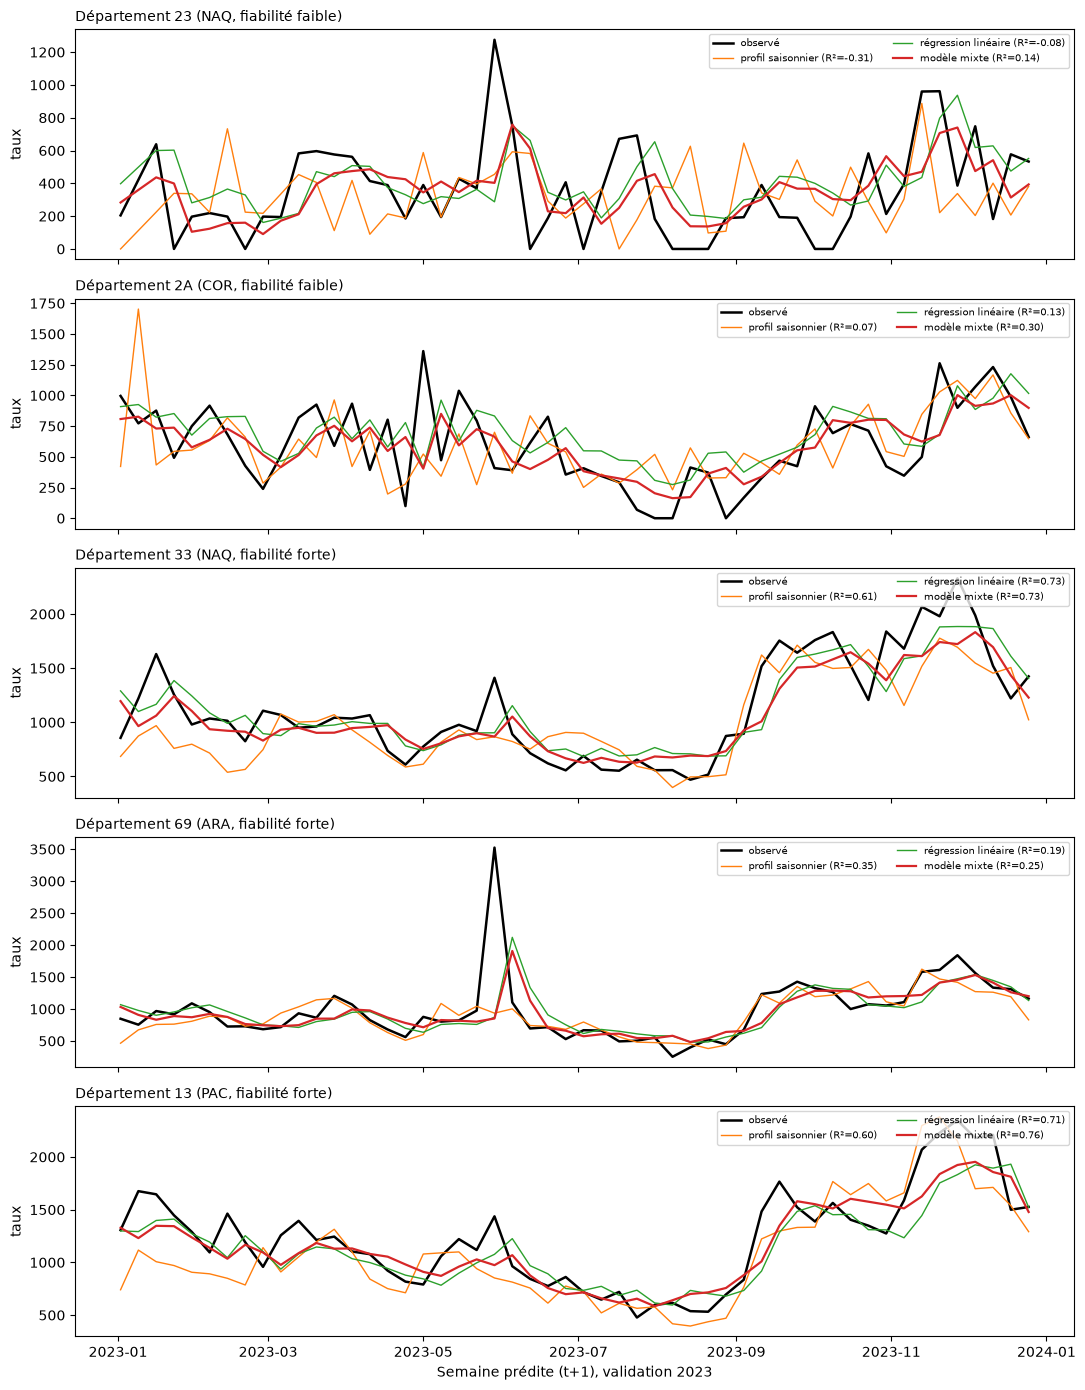

In [32]:
import statsmodels.formula.api as smf

ECHELLE = 100                                                   # cible ajustée en centaines (aide la convergence)

# --- 1) Table pour le modèle mixte : région et deux harmoniques saisonniers ---
pm = panel.copy()
pm["region"] = pm["code_dept"].map(dept_region)
pm["s1"], pm["c1"] = pm["sem_sin"], pm["sem_cos"]              # 1er harmonique (période 1 an)
pm["s2"] = 2 * pm["s1"] * pm["c1"]                              # 2e harmonique (période 6 mois),
pm["c2"] = pm["c1"] ** 2 - pm["s1"] ** 2                        # déduit du 1er par trigonométrie

tr_mm = pm[pm["split"] == "train"].dropna(subset=["cible", "region"]).copy()
tr_mm["cible_ech"] = tr_mm["cible"] / ECHELLE
# Validation : mêmes lignes que la régression linéaire (FEATURES complètes) et que les baselines
va_mm = pm[pm["split"] == "val"].dropna(subset=FEATURES + ["cible", "region", "base_saison"]).copy()

# --- 2) Modèle mixte ---
# Fixe   : lags + courbe saisonnière par région (niveau et forme)
# Aléatoire, par département : écart de niveau + écart d'amplitude/phase saisonnière (1er harmonique)
FORMULE = "cible_ech ~ y_lag0 + y_lag1 + y_lag2 + C(region) * (s1 + c1 + s2 + c2)"
RE      = "1 + s1 + c1"
mm = smf.mixedlm(FORMULE, tr_mm, groups=tr_mm["code_dept"], re_formula=RE).fit(
         method=["lbfgs", "powell"], maxiter=2000)
print("Convergence :", mm.converged)
print("Coefficients des lags :\n", (ECHELLE * mm.fe_params[["y_lag0", "y_lag1", "y_lag2"]]).round(3))

# --- 3) Prédictions sur la validation (remises en unités d'origine) ---
re = pd.DataFrame(mm.random_effects).T                           # une ligne par département, colonnes = (1, s1, c1)
Z = np.column_stack([np.ones(len(va_mm)), va_mm["s1"], va_mm["c1"]])
va_mm["pred_MM_fixe"] = ECHELLE * mm.predict(va_mm).values       # sans effets départementaux
va_mm["pred_MM"] = va_mm["pred_MM_fixe"] + ECHELLE * (Z * re.loc[va_mm["code_dept"]].values).sum(axis=1)
va_mm["pred_LR"] = modele.predict(va_mm[FEATURES])

# --- 4) Comparaison, au total et par fiabilité des séries ---
fiab = pd.qcut(ind["r2_persist"], 3, labels=["faible", "moyenne", "forte"])
va_mm["fiabilite"] = va_mm["code_dept"].map(fiab)

cols = {"persistance": "base_persist", "profil": "base_saison", "LR": "pred_LR",
        "MM fixe": "pred_MM_fixe", "MM complet": "pred_MM"}
tab = {k: {nom: scores(g["cible"], g[c])["R2"] for nom, c in cols.items()}
       for k, g in va_mm.groupby("fiabilite", observed=True)}
tab["TOTAL"] = {nom: scores(va_mm["cible"], va_mm[c])["R2"] for nom, c in cols.items()}
print(f"\nR² validation 2023 (H = {H}, {len(va_mm)} lignes) :")
print(pd.DataFrame(tab).T.round(3))

DEPTS = ["23", "2A", "33", "69", "13"]                          # départements à afficher

COURBES = [("base_saison", "profil saisonnier", "tab:orange", 1.0),
           ("pred_LR",     "régression linéaire", "tab:green", 1.0),
           ("pred_MM",     "modèle mixte", "tab:red", 1.6)]

fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.8 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = va_mm[va_mm["code_dept"] == dept].sort_values("date_debut")
    ax.plot(v["date_debut"], v["cible"], color="black", lw=1.8, label="observé")
    for col, nom, coul, ep in COURBES:
        r2 = scores(v["cible"], v[col])["R2"]
        ax.plot(v["date_debut"], v[col], color=coul, lw=ep, label=f"{nom} (R²={r2:.2f})")
    fiab_d = v["fiabilite"].iloc[0] if len(v) else "?"
    ax.set_title(f"Département {dept} ({dept_region.get(dept, '?')}, fiabilité {fiab_d})",
                 fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Semaine prédite (t+1), validation 2023")
plt.tight_layout()
plt.show()